# Compare MSA generation

In [1]:
import glob
import json
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.axes import Axes
from matplotlib.ticker import PercentFormatter
from scipy import stats
from sklearn.metrics import roc_auc_score
from statsmodels.stats.anova import AnovaRM

In [2]:
sequences = pd.read_csv('../data/interim/sequences_sample_50.csv')
sequences['index'] = sequences['index'].apply(str)
sequences = sequences.set_index('index')
sequences['type'] = sequences['label'].map(lambda label: 'binder' if label else 'decoy')

In [3]:
with open('../data/interim/sequence_key.txt') as fh:
    sequence_key = {sequence: key for key, sequence in (line.split() for line in fh if line)}

In [4]:
full_sequences = pd.read_csv('../data/interim/sequences_full.csv')
full_sequences['id'] = full_sequences['id'].apply(str)
full_sequences = full_sequences.set_index('id')

## MSA generation time

In [5]:
msa_ids = set(full_sequences.melt(ignore_index=False)['value'].map(sequence_key).dropna().loc[sequences.index].tolist())

In [6]:
timings = []
for path in glob.glob('../data/benchmarks/msa-generation_*.tsv'):
    timing = pd.read_csv(path, delimiter='\t')

    method_info = re.search(
        'msa-generation_(?P<msa_method>[a-zA-Z0-9]+)(?:_(?P<data_source>[a-zA-Z0-9]+))?_(?P<id>[a-zA-Z0-9]+).tsv', path
    ).groupdict()

    for key, val in method_info.items():
        timing[key] = val

    timings.append(timing)

timings = pd.concat(timings).reset_index(drop=True)
timings = timings[timings['id'].isin(msa_ids)].copy()

In [7]:
def format_time(seconds: int) -> str:
    hours = seconds // 3600
    minutes = (seconds % 3600) // 60
    secs = seconds % 60
    parts = []
    if hours > 0:
        parts.append(f'{int(hours)} hours')

    if minutes > 0:
        parts.append(f'{int(minutes)} mins')

    if secs > 0 or not parts:
        parts.append(f'{int(secs)} secs')

    return ', '.join(parts)

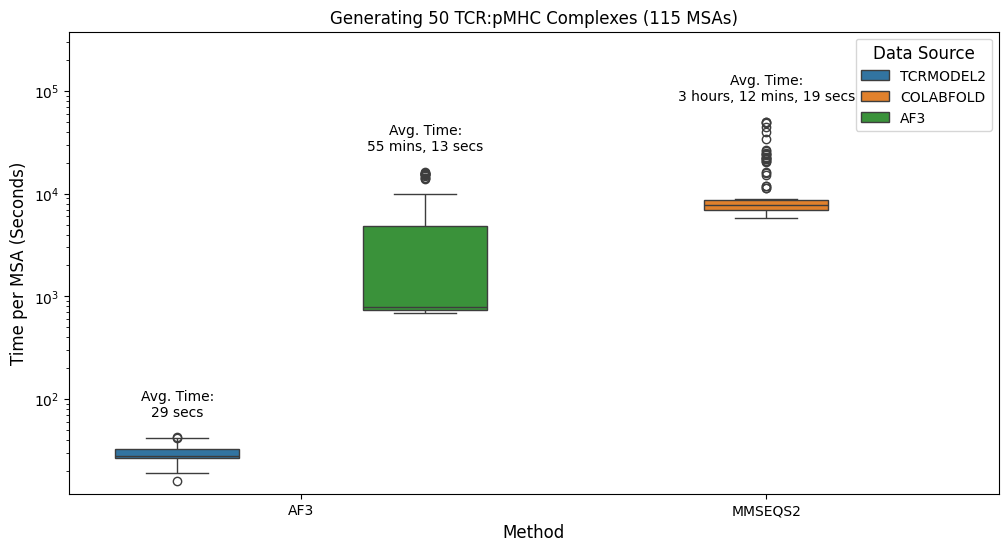

In [8]:
plt.figure(figsize=(12, 6))
plt.title('Generating 50 TCR:pMHC Complexes (115 MSAs)')

ax = sns.boxplot(timings, y='s', x='msa_method', hue='data_source')
ax.set(yscale='log')

ax.set_xlabel('Method', fontsize=12)
ax.set_ylabel('Time per MSA (Seconds)', fontsize=12)


groups = timings.groupby(['msa_method', 'data_source'])

x_labels = [tick_label.get_text() for tick_label in ax.get_xticklabels()]
handles, hue_labels = ax.get_legend_handles_labels()

n_x = len(x_labels)
n_hue = len(hue_labels)
positions = np.arange(n_x)

total_width = 0.8
box_width = total_width / n_hue

for i, x_label in enumerate(x_labels):
    for j, hue_label in enumerate(hue_labels):
        if (x_label, hue_label) not in groups.groups:
            continue

        group = groups.get_group((x_label, hue_label))
        x_pos = positions[i] - total_width / 2 + box_width * (j + 0.5)

        ax.text(
            x_pos,
            group['s'].max() * 1.5,
            f"Avg. Time:\n{format_time(group['s'].mean())}",
            ha='center',
            va='bottom',
        )

leg = ax.legend(title='Data Source', title_fontsize=12)
for text in leg.get_texts():
    text.set_text(text.get_text().upper())

ax.set_ylim(timings['s'].min() * 0.75, timings['s'].max() * 7.5)
ax.set_xticks(ax.get_xticks())
ax.set_xticklabels([label.get_text().upper() for label in ax.get_xticklabels()])

plt.show()

## Antigen Specificity

In [9]:
confidences = []
for path in glob.glob('../data/processed/confidence_scores_*_50.csv'):
    confidence_scores = pd.read_csv(path)
    info = re.search(
        r'confidence_scores_(?P<msa_method>[a-zA-Z0-9]+)_(?P<data_source>[a-zA-Z0-9]+)_(?P<sample_size>\d+).csv',
        os.path.basename(path),
    )

    for key, value in info.groupdict().items():
        confidence_scores[key] = value

    confidences.append(confidence_scores)

confidences = pd.concat(confidences)
confidences['structure_name'] = confidences['structure_name'].apply(str)

In [10]:
confidences = confidences.merge(sequences, how='left', left_on='structure_name', right_on='index')

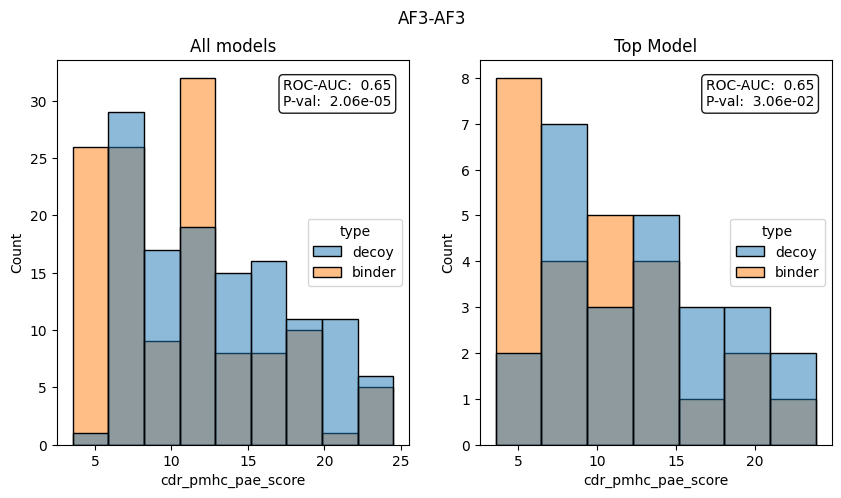

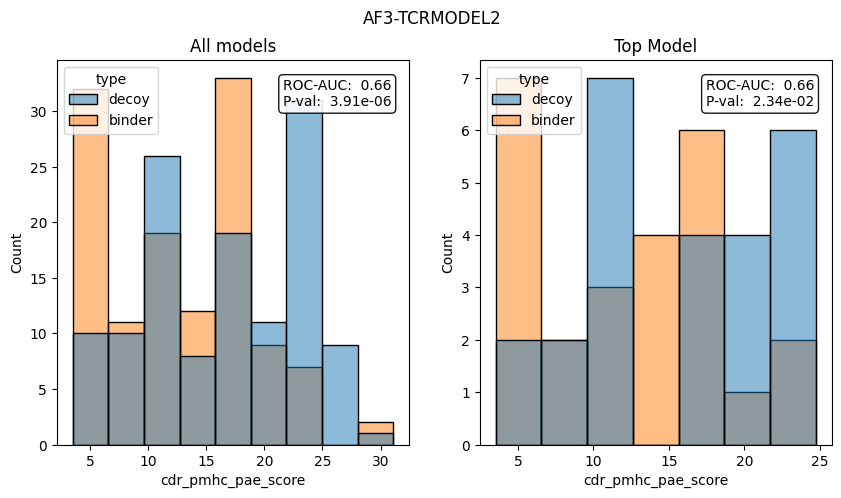

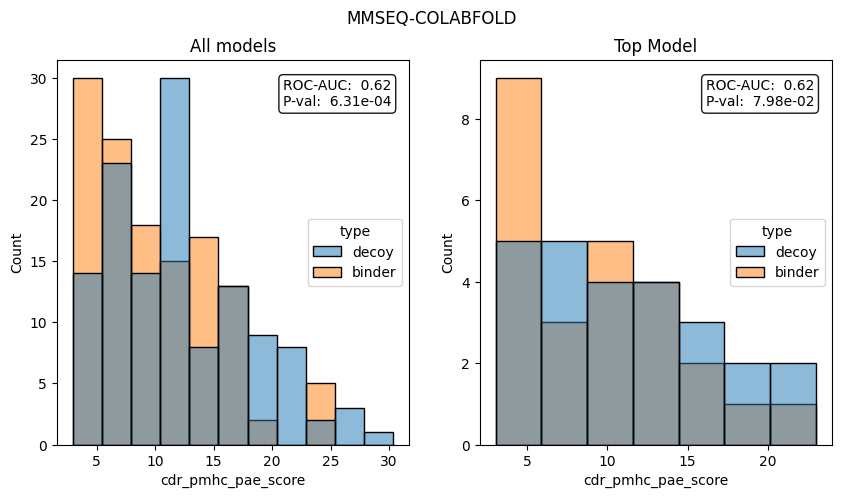

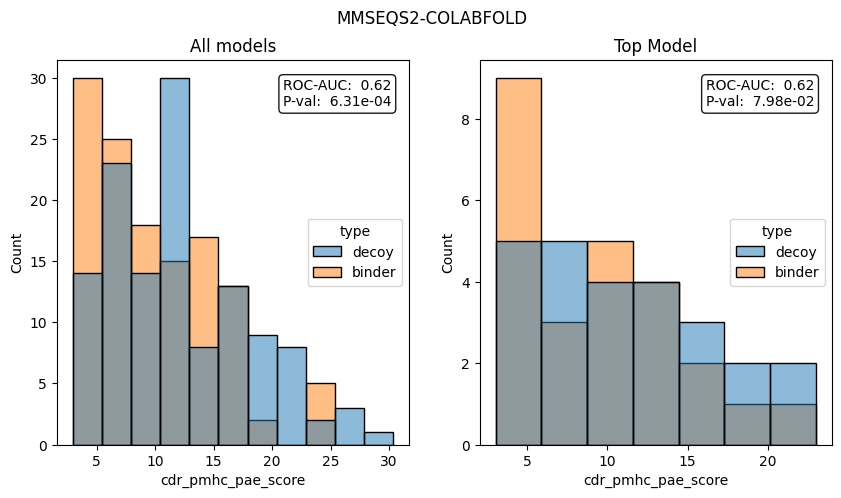

In [11]:
for name, group in confidences.groupby(['msa_method', 'data_source']):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
    fig.suptitle('-'.join(name).upper())

    sns.histplot(group, x='cdr_pmhc_pae_score', hue='type', ax=ax1)
    ax1.set_title('All models')

    roc_auc = 1 - roc_auc_score(group['label'], group['cdr_pmhc_pae_score'])
    stat, p_val = stats.ranksums(
        group.query("type == 'binder'")['cdr_pmhc_pae_score'],
        group.query("type == 'decoy'")['cdr_pmhc_pae_score'],
        alternative='less',
    )
    ax1.text(
        0.95,
        0.95,
        f'ROC-AUC: {roc_auc: .2f}\nP-val: {p_val: .2e}',
        transform=ax1.transAxes,
        verticalalignment='top',
        horizontalalignment='right',
        bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
    )

    group_top_model = group.query('top_model')
    sns.histplot(group_top_model, x='cdr_pmhc_pae_score', hue='type', ax=ax2)
    ax2.set_title('Top Model')

    roc_auc_top_model = 1 - roc_auc_score(group_top_model['label'], group_top_model['cdr_pmhc_pae_score'])
    stat_top_model, p_val_top_model = stats.ranksums(
        group_top_model.query("type == 'binder'")['cdr_pmhc_pae_score'],
        group_top_model.query("type == 'decoy'")['cdr_pmhc_pae_score'],
        alternative='less',
    )
    ax2.text(
        0.95,
        0.95,
        f'ROC-AUC: {roc_auc_top_model: .2f}\nP-val: {p_val_top_model: .2e}',
        transform=ax2.transAxes,
        verticalalignment='top',
        horizontalalignment='right',
        bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
    )

In [12]:
NUM_SAMPLES = 15
SAMPLE_SIZE = 20

rng = np.random.default_rng(123)

structure_names = sorted(confidences['structure_name'].unique())

roc_aucs = {
    'sample_number': [],
    'msa_method': [],
    'data_source': [],
    'roc_auc': [],
    'roc_auc_top': [],
}

for sample_number in range(1, NUM_SAMPLES + 1):
    sampled_structure_names = rng.choice(structure_names, SAMPLE_SIZE, replace=False)

    for (msa_method, data_source), group in confidences.groupby(['msa_method', 'data_source']):
        sample = group[group['structure_name'].isin(sampled_structure_names)]
        sample_top_model = sample.query('top_model')

        roc_aucs['sample_number'].append(sample_number)
        roc_aucs['msa_method'].append(msa_method)
        roc_aucs['data_source'].append(data_source)
        roc_aucs['roc_auc'].append(1 - roc_auc_score(sample['label'], sample['cdr_pmhc_pae_score']))
        roc_aucs['roc_auc_top'].append(
            1 - roc_auc_score(sample_top_model['label'], sample_top_model['cdr_pmhc_pae_score'])
        )

roc_aucs = pd.DataFrame(roc_aucs)

In [13]:
roc_aucs = roc_aucs.melt(
    id_vars=['sample_number', 'msa_method', 'data_source'],
    value_vars=['roc_auc', 'roc_auc_top'],
    var_name='type',
    value_name='score',
)
roc_aucs['type'] = roc_aucs['type'].map({'roc_auc': 'all', 'roc_auc_top': 'top'})

In [14]:
roc_aucs['msa_method_data_source'] = roc_aucs['msa_method'] + '-' + roc_aucs['data_source']

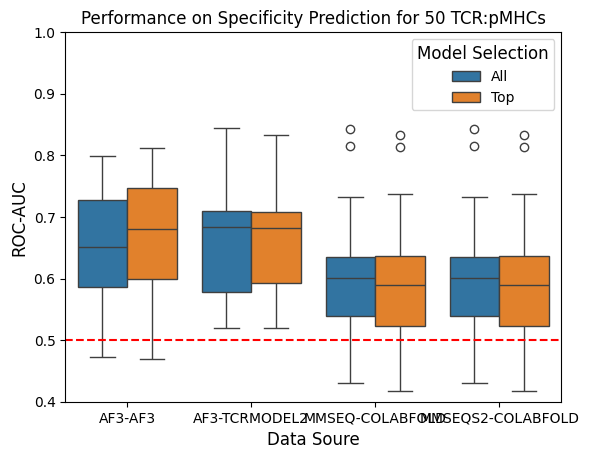

In [15]:
ax = sns.boxplot(roc_aucs, x='msa_method_data_source', y='score', hue='type')

ax.axhline(0.5, color='red', linestyle='dashed')

ax.set_ylim((0.40, 1.0))

ax.set_ylabel('ROC-AUC', fontsize=12)
ax.set_xlabel('Data Soure', fontsize=12)

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels([label.get_text().upper() for label in ax.get_xticklabels()])

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, [label.title() for label in labels], title='Model Selection', title_fontsize=12)

ax.set_title('Performance on Specificity Prediction for 50 TCR:pMHCs', fontsize=12)

plt.show()

In [16]:
aovrm = AnovaRM(roc_aucs, depvar='score', subject='sample_number', within=['msa_method_data_source', 'type'])
res = aovrm.fit()
print(res)

                          Anova
                            F Value Num DF  Den DF Pr > F
---------------------------------------------------------
msa_method_data_source       3.0449 3.0000 42.0000 0.0391
type                         0.0136 1.0000 14.0000 0.9087
msa_method_data_source:type  5.1544 3.0000 42.0000 0.0040



## DockQ

In [17]:
CAPRI_ACCEPTABLE_CUTOFF = 0.23
CAPRI_MEDIUM_CUTOFF = 0.49
CAPRI_HIGH_CUTOFF = 0.80


def get_capri_classification(dockq: float) -> str:
    if dockq < CAPRI_ACCEPTABLE_CUTOFF:
        return 'Incorrect'

    if CAPRI_ACCEPTABLE_CUTOFF <= dockq < CAPRI_MEDIUM_CUTOFF:
        return 'Acceptable'

    if CAPRI_MEDIUM_CUTOFF <= dockq < CAPRI_HIGH_CUTOFF:
        return 'Medium'

    return 'High'

In [18]:
dockq_scores = []
for path in glob.glob('../data/processed/predicted_*_dockq_benchmark.csv'):
    dockq_score = pd.read_csv(path)
    info = re.search(
        r'predicted_(?P<msa_method>[a-zA-Z0-9]+)_(?P<data_source>[a-zA-Z0-9]+)_dockq_benchmark.csv',
        os.path.basename(path),
    )

    for key, value in info.groupdict().items():
        dockq_score[key] = value

    dockq_scores.append(dockq_score)

dockq_scores = pd.concat(dockq_scores).reset_index(drop=True)

In [19]:
dockq_scores['capri_classification'] = dockq_scores['DockQ'].map(get_capri_classification)

In [20]:
def get_ranking_score(msa_method: str, data_source: str, name: str, seed: int, sample: int) -> float:
    confidence_path = os.path.join(
        '..',
        'data',
        'interim',
        f'structures_{msa_method}_{data_source}',
        f'{name}_seed-{seed}_sample-{sample}_summary_confidences.json',
    )
    with open(confidence_path, 'r') as fh:
        confidences = json.load(fh)

    return float(confidences['ranking_score'])


dockq_scores['ranking_score'] = dockq_scores.apply(
    lambda row: get_ranking_score(row['msa_method'], row['data_source'], row['name'], row['seed'], row['sample']),
    axis='columns',
)

In [21]:
dockq_scores['top_model'] = False
dockq_scores.loc[dockq_scores.groupby(['name', 'msa_method', 'data_source'])['ranking_score'].idxmax(), 'top_model'] = (
    True
)

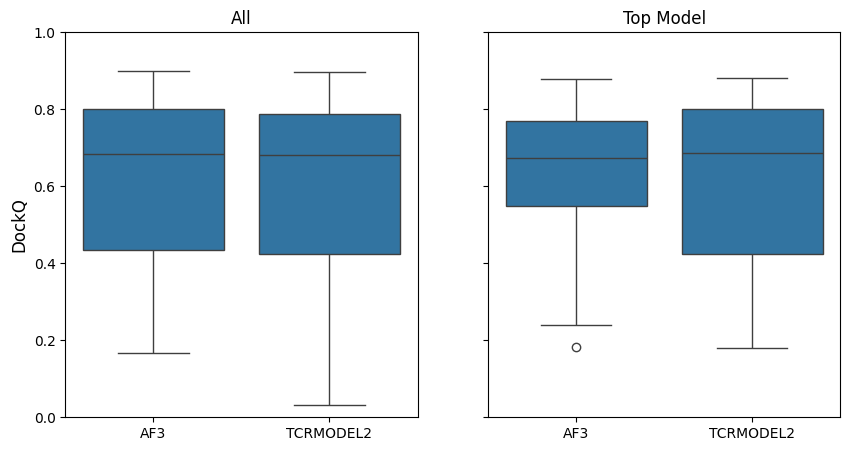

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].set_title('All')
sns.boxplot(dockq_scores.sort_values('data_source'), y='DockQ', x='data_source', ax=axes[0])

axes[0].set_ylim(0, 1)
axes[0].set_ylabel(axes[0].get_ylabel(), fontsize=12)
axes[0].set_xticks(axes[0].get_xticks())
axes[0].set_xticklabels([label.get_text().upper() for label in axes[0].get_xticklabels()])
axes[0].set_xlabel('')

axes[1].set_title('Top Model')
sns.boxplot(dockq_scores.sort_values('data_source').query('top_model'), y='DockQ', x='data_source', ax=axes[1])

axes[1].set_ylim(0, 1)
axes[1].set_ylabel('')
axes[1].set_yticklabels([])
axes[1].set_xticks(axes[1].get_xticks())
axes[1].set_xticklabels([label.get_text().upper() for label in axes[1].get_xticklabels()])
axes[1].set_xlabel('')

plt.show()

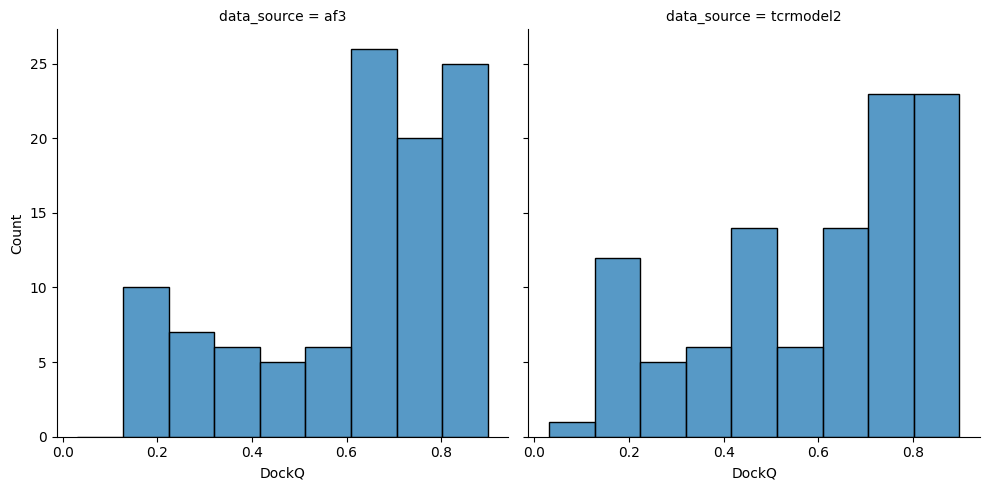

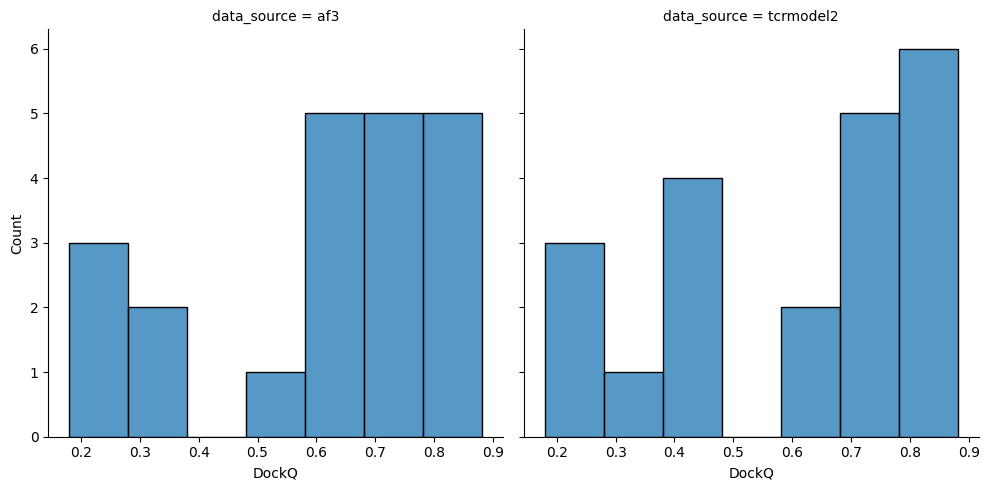

In [23]:
sns.displot(dockq_scores.sort_values('data_source'), x='DockQ', col='data_source', kind='hist')
plt.show()
sns.displot(dockq_scores.query('top_model').sort_values('data_source'), x='DockQ', col='data_source', kind='hist')
plt.show()

In [24]:
def get_significance(dockq_scores: pd.DataFrame) -> tuple[float, float]:
    (_, group_af3), (_, group_tcrmodel2) = (
        dockq_scores.sort_values(['data_source', 'name', 'seed', 'sample'])
        .set_index(['name', 'seed', 'sample'])
        .groupby('data_source')
    )

    comparison = group_af3.merge(
        group_tcrmodel2, how='inner', left_index=True, right_index=True, suffixes=('_af3', '_tcrmodel2')
    )
    stat, p_val = stats.wilcoxon(comparison['DockQ_af3'], comparison['DockQ_tcrmodel2'])

    return stat, p_val


print('All p-value:', get_significance(dockq_scores)[1])
print('Top Model p-value:', get_significance(dockq_scores.query('top_model'))[1])

All p-value: 0.22520248019422595
Top Model p-value: 0.275390625


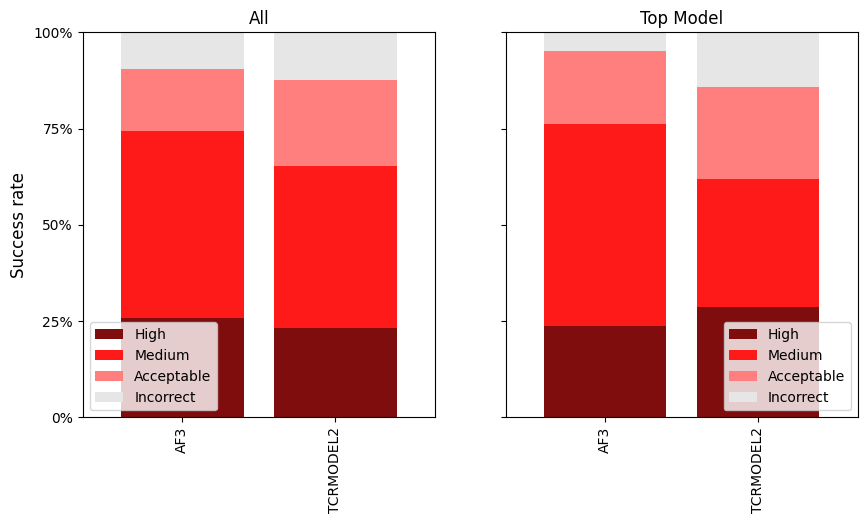

In [25]:
def plot_capri_classification(dockq_scores: pd.DataFrame, ax: Axes | None = None) -> Axes:
    capri_classification = (
        dockq_scores.groupby('data_source')['capri_classification'].value_counts(normalize=True) * 100
    )
    capri_classification.name = 'percent'
    capri_classification = capri_classification.reset_index()
    capri_classification = capri_classification.pivot_table(
        index='data_source', columns='capri_classification', values='percent'
    )

    order = ['High', 'Medium', 'Acceptable', 'Incorrect']
    colours = {
        'High': '#7f0d0d',
        'Medium': '#ff1a1a',
        'Acceptable': '#ff7f7f',
        'Incorrect': '#e6e6e6',
    }

    plot_ax = capri_classification.reindex(columns=order, fill_value=0).plot(
        kind='bar', stacked=True, color=[colours[col_name] for col_name in order], width=0.8, edgecolor='none', ax=ax
    )

    plot_ax.set_ylim(0, 100)
    plot_ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
    plot_ax.set_ylabel('Success rate', fontsize=12)
    plot_ax.set_yticks([0, 25, 50, 75, 100])
    plot_ax.set_xlabel('')
    plot_ax.set_xticklabels([label.get_text().upper() for label in plot_ax.get_xticklabels()])
    plot_ax.legend(title='')

    return plot_ax


fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].set_title('All')
plot_capri_classification(dockq_scores, ax=axes[0])

axes[1].set_title('Top Model')
plot_capri_classification(dockq_scores.query('top_model'), ax=axes[1])

axes[1].set_yticklabels([])
axes[1].set_ylabel('')

plt.show()